# Agrupar donde no hay grupos

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 10, unidad 4 · Genera la figura de la lámina «El experimento decisivo»

---

La clase afirma tres cosas y aquí se miden las tres:

1. Que **todos los algoritmos encuentran grupos siempre**, incluso sobre datos
   uniformes sin ninguna estructura.
2. Que **el índice de silueta no avisa**: produce un máximo y ese máximo señala
   un «número óptimo de grupos» que no existe.
3. Que lo que **sí** distingue estructura real de estructura inventada es
   comparar contra una referencia nula y medir estabilidad.

## El diseño

Se comparan dos conjuntos de datos con **exactamente el mismo número de puntos y
el mismo rango**:

| Conjunto | Estructura |
|---|---|
| `con_grupos` | Cuatro grupos gaussianos bien separados |
| `sin_grupos` | Puntos **uniformes** en el mismo cuadrado, sin ninguna estructura |

Todo lo que distinga a uno de otro es lo que un método de validación debería
detectar.

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0
matplotlib    3.10.9


In [2]:
SEMILLA = 14
N_PUNTOS = 600
K_RANGO = range(2, 11)
N_NULOS = 20          # réplicas de la referencia nula
N_SUBMUESTRAS = 30    # réplicas para medir estabilidad
FRACCION = 0.80

print(f"Puntos por conjunto: {N_PUNTOS}")
print(f"k evaluados: {list(K_RANGO)}")

Puntos por conjunto: 600
k evaluados: [2, 3, 4, 5, 6, 7, 8, 9, 10]


## 2. Los dos conjuntos

El conjunto sin estructura se genera **uniforme dentro del rango observado** del
conjunto con grupos. Así ambos ocupan la misma región del plano y la comparación
no se explica por la escala.

In [3]:
rng = np.random.default_rng(SEMILLA)

con_grupos, etiquetas_verdaderas = make_blobs(
    n_samples=N_PUNTOS, centers=4, cluster_std=0.60,
    center_box=(-6, 6), random_state=SEMILLA)

minimos, maximos = con_grupos.min(axis=0), con_grupos.max(axis=0)
sin_grupos = rng.uniform(minimos, maximos, size=(N_PUNTOS, 2))

print(f"con_grupos:  {con_grupos.shape}, rango x [{minimos[0]:.1f}, {maximos[0]:.1f}]")
print(f"sin_grupos:  {sin_grupos.shape}, rango x [{sin_grupos[:,0].min():.1f}, "
      f"{sin_grupos[:,0].max():.1f}]")

con_grupos:  (600, 2), rango x [-3.9, 5.7]
sin_grupos:  (600, 2), rango x [-3.9, 5.7]


## 3. La silueta sobre ambos conjuntos

Se aplica $k$-medias con $k$ de 2 a 10 y se calcula la silueta media. Si el
índice sirviera para detectar ausencia de estructura, en `sin_grupos` debería
dar valores próximos a cero y sin máximo claro.

In [4]:
def siluetas(X):
    valores = []
    for k in K_RANGO:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
        valores.append(silhouette_score(X, km.labels_))
    return np.array(valores)

sil_con = siluetas(con_grupos)
sil_sin = siluetas(sin_grupos)

print(f"{'k':>4} {'con grupos':>13} {'sin grupos':>13}")
print("-" * 32)
for i, k in enumerate(K_RANGO):
    m1 = " <-" if i == int(np.argmax(sil_con)) else "   "
    m2 = " <-" if i == int(np.argmax(sil_sin)) else ""
    print(f"{k:>4} {sil_con[i]:>13.3f}{m1} {sil_sin[i]:>10.3f}{m2}")

k_con = list(K_RANGO)[int(np.argmax(sil_con))]
k_sin = list(K_RANGO)[int(np.argmax(sil_sin))]
print()
print(f"«k óptimo» según la silueta, con grupos:  {k_con}   (verdadero: 4)")
print(f"«k óptimo» según la silueta, SIN grupos:  {k_sin}   (verdadero: no hay)")

   k    con grupos    sin grupos
--------------------------------
   2         0.669         0.441 <-
   3         0.727         0.410
   4         0.737 <-      0.420
   5         0.637         0.417
   6         0.558         0.393
   7         0.406         0.380
   8         0.333         0.373
   9         0.337         0.383
  10         0.352         0.392

«k óptimo» según la silueta, con grupos:  4   (verdadero: 4)
«k óptimo» según la silueta, SIN grupos:  2   (verdadero: no hay)


**El índice devuelve un máximo también donde no hay nada que encontrar.** No
dice «aquí no hay estructura»: dice un número, y ese número parece una respuesta.

Lo que sí distingue a los dos conjuntos es la **magnitud**: la silueta del
conjunto con grupos es mucho mayor. Pero esa magnitud solo es interpretable si
se tiene con qué compararla —y eso es la sección siguiente.

## 4. La referencia nula

Para cada conjunto se generan réplicas **sin estructura** con el mismo rango, y
se compara la silueta observada con la distribución de siluetas del nulo.

Es la idea de la estadística de brecha, en su forma más simple y directa.

In [5]:
def silueta_nula(X, k, n_replicas=N_NULOS, semilla=0):
    """Distribución de la silueta sobre datos uniformes del mismo rango."""
    r = np.random.default_rng(semilla)
    lo, hi = X.min(axis=0), X.max(axis=0)
    valores = []
    for _ in range(n_replicas):
        Z = r.uniform(lo, hi, size=X.shape)
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
        valores.append(silhouette_score(Z, km.labels_))
    return np.array(valores)

print(f"{'conjunto':>12} {'k':>4} {'silueta':>10} {'nulo (mediana)':>16} "
      f"{'nulo (máx)':>12} {'¿supera?':>10}")
print("-" * 70)
for nombre, X, k in [("con grupos", con_grupos, k_con), ("sin grupos", sin_grupos, k_sin)]:
    obs = silhouette_score(X, KMeans(n_clusters=k, n_init=10,
                                     random_state=SEMILLA).fit(X).labels_)
    nulo = silueta_nula(X, k, semilla=SEMILLA + 1)
    supera = "sí" if obs > nulo.max() else "NO"
    print(f"{nombre:>12} {k:>4} {obs:>10.3f} {np.median(nulo):>16.3f} "
          f"{nulo.max():>12.3f} {supera:>10}")

    conjunto    k    silueta   nulo (mediana)   nulo (máx)   ¿supera?
----------------------------------------------------------------------


  con grupos    4      0.737            0.390        0.414         sí


  sin grupos    2      0.441            0.441        0.467         NO


Ahora sí hay una respuesta interpretable. En el conjunto con grupos, la silueta
observada **supera con holgura** cualquier valor alcanzado por el nulo. En el
conjunto sin grupos, cae **dentro** del rango del nulo: no hay evidencia de
estructura.

El índice no cambió. Lo que cambió es que ahora tiene con qué compararse.

## 5. Estabilidad, y un resultado que no esperábamos

La segunda comprobación de la clase: si los grupos son reales, deberían aparecer
también en una submuestra. Se agrupa repetidamente sobre el 80 % de los datos y
se mide cuánto coinciden las particiones en los puntos compartidos, con el
**índice de Rand ajustado** —que vale 0 para coincidencias al azar.

Antes de mirar el resultado, prediga: ¿esperaría que el conjunto uniforme sea
inestable?

In [6]:
def estabilidad(X, k, n_replicas=N_SUBMUESTRAS, semilla=0):
    r = np.random.default_rng(semilla)
    n = len(X)
    particiones = []
    for _ in range(n_replicas):
        idx = r.choice(n, int(FRACCION * n), replace=False)
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X[idx])
        etiquetas = np.full(n, -1)
        etiquetas[idx] = km.labels_
        particiones.append(etiquetas)

    concordancias = []
    for i in range(len(particiones)):
        for j in range(i + 1, len(particiones)):
            comun = (particiones[i] >= 0) & (particiones[j] >= 0)
            if comun.sum() > 10:
                concordancias.append(
                    adjusted_rand_score(particiones[i][comun], particiones[j][comun]))
    return np.array(concordancias)

print(f"{'conjunto':>12} {'k':>4} {'Rand ajustado (mediana)':>26} {'RIC':>20}")
print("-" * 66)
for nombre, X, k in [("con grupos", con_grupos, k_con), ("sin grupos", sin_grupos, k_sin)]:
    c = estabilidad(X, k, semilla=SEMILLA + 2)
    q1, q3 = np.percentile(c, [25, 75])
    print(f"{nombre:>12} {k:>4} {np.median(c):>26.3f} "
          f"[{q1:.3f}, {q3:.3f}]".rjust(21))

    conjunto    k    Rand ajustado (mediana)                  RIC
------------------------------------------------------------------


  con grupos    4                      1.000 [1.000, 1.000]


  sin grupos    2                      0.979 [0.944, 0.990]


In [7]:
# ¿Ocurre solo en el k elegido, o en todo el rango?
print(f"{'k':>4} {'con grupos':>13} {'sin grupos':>13}")
print("-" * 32)
est_por_k = {}
for k in K_RANGO:
    ec = np.median(estabilidad(con_grupos, k, semilla=SEMILLA + 2))
    es = np.median(estabilidad(sin_grupos, k, semilla=SEMILLA + 2))
    est_por_k[k] = (ec, es)
    print(f"{k:>4} {ec:>13.3f} {es:>13.3f}")

   k    con grupos    sin grupos
--------------------------------


   2         1.000         0.979


   3         1.000         0.968


   4         1.000         0.959


   5         0.830         0.833


   6         0.773         0.774


   7         0.701         0.631


   8         0.718         0.737


   9         0.711         0.756


  10         0.742         0.865


**El conjunto sin estructura es casi tan estable como el que tiene grupos
reales.** Y no es un accidente de este $k$: la tabla siguiente lo recorre entero.

La razón es geométrica y, una vez vista, evidente. Sobre un rectángulo uniforme,
$k$-medias con $k=2$ **siempre** parte por la mitad del lado más largo. Es una
solución determinista de un problema determinista, así que se reproduce
perfectamente en cualquier submuestra.

**La estabilidad mide si la solución del algoritmo es reproducible, no si hay
estructura en los datos.** Son cosas distintas, y este cuaderno las separa.

Es un resultado conocido —Ben-David, von Luxburg y Pál (2006) lo demuestran en
general— y contradice el uso habitual de la estabilidad como evidencia de que
los grupos existen.

Lo que sí se sostiene es la implicación en un solo sentido:

- Estabilidad **baja** → los grupos **no** son fiables. Es una refutación válida.
- Estabilidad **alta** → no dice nada. Puede haber estructura, o puede ser
  geometría del algoritmo.

## 6. La conclusión: qué distingue de verdad

Poniendo juntos los dos métodos sobre los mismos datos:

| Método | ¿Separa el caso con grupos del caso sin grupos? |
|---|---|
| **Silueta sola** | **No.** Da un máximo en ambos |
| **Silueta frente a referencia nula** | **Sí**, y con holgura |
| **Estabilidad** | **No.** Ambos son estables |

La referencia nula es lo único de los tres que respondió la pregunta correcta,
porque es el único que **compara contra la ausencia de estructura** en vez de
describir la partición obtenida.

Y falta el método que la clase pone por encima de todos y que este cuaderno no
puede ejercer: **la utilidad para una tarea posterior**. Si los grupos mejoran
una decisión medible, o corresponden a algo que no se usó para construirlos, esa
es la evidencia que convence a un revisor.

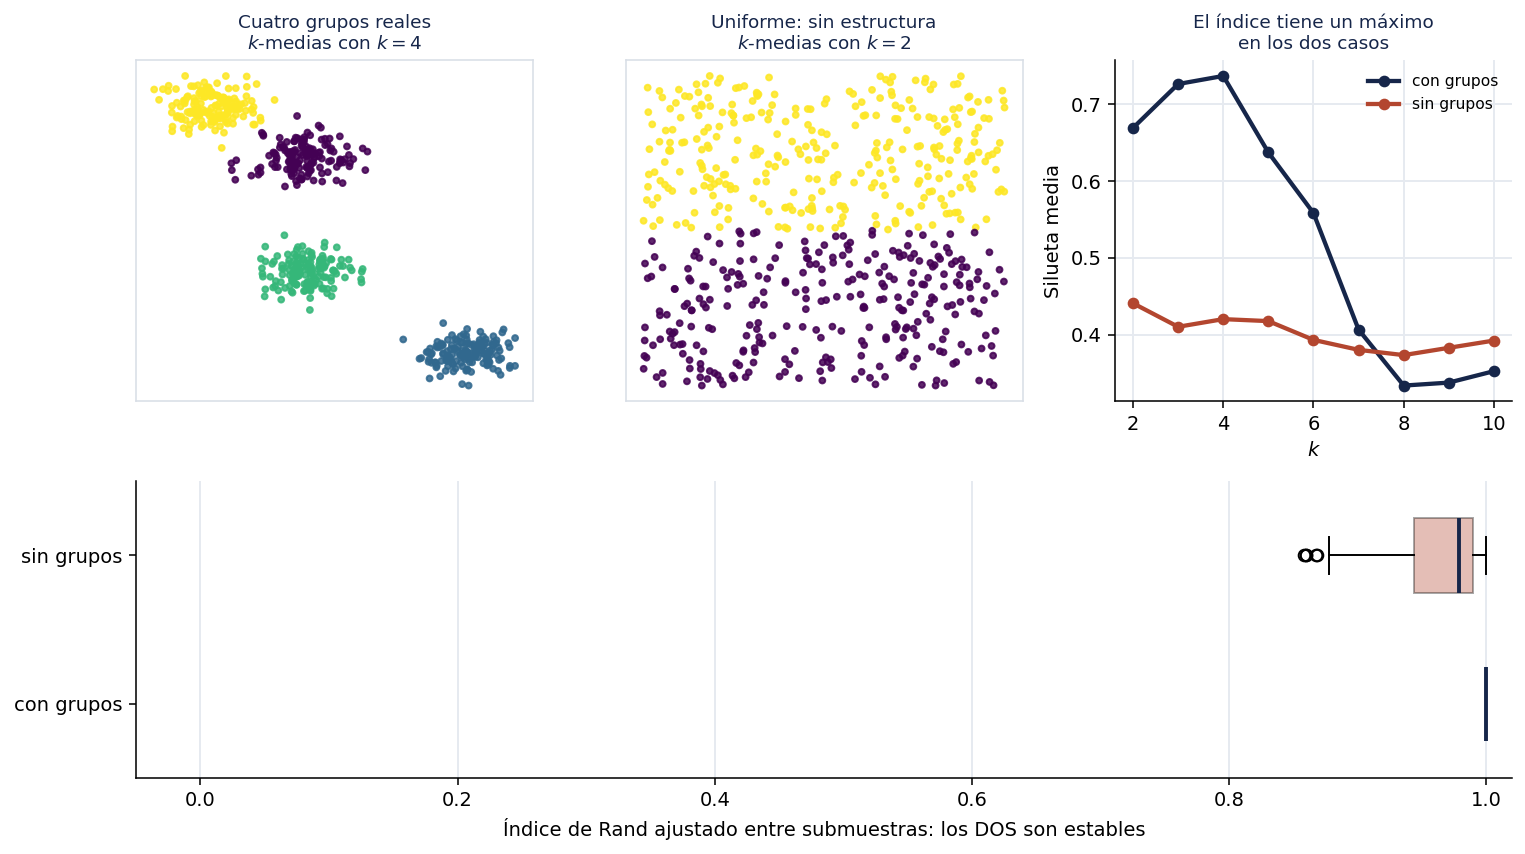

In [8]:
#| label: fig-agrupamiento
#| fig-cap: "Silueta y estabilidad sobre datos con estructura y sobre datos uniformes."
fig = plt.figure(figsize=(11, 6.2), dpi=140)
gs = fig.add_gridspec(2, 3, height_ratios=[1.15, 1])

for col, (nombre, X) in enumerate([("Cuatro grupos reales", con_grupos),
                                   ("Uniforme: sin estructura", sin_grupos)]):
    k = k_con if col == 0 else k_sin
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    ax = fig.add_subplot(gs[0, col])
    ax.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="viridis", s=9, alpha=0.85)
    ax.set_title(f"{nombre}\n$k$-medias con $k={k}$", fontsize=9.5, color="#16264A")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("#D8DEE6")

ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(list(K_RANGO), sil_con, "o-", lw=2.2, ms=5, color="#16264A",
         label="con grupos")
ax3.plot(list(K_RANGO), sil_sin, "o-", lw=2.2, ms=5, color="#B3462F",
         label="sin grupos")
ax3.set_xlabel("$k$"); ax3.set_ylabel("Silueta media")
ax3.set_title("El índice tiene un máximo\nen los dos casos", fontsize=9.5, color="#16264A")
ax3.spines[["top", "right"]].set_visible(False)
ax3.grid(color="#E6EAF0", lw=1); ax3.set_axisbelow(True)
ax3.legend(frameon=False, fontsize=8)

ax4 = fig.add_subplot(gs[1, :])
etiquetas = ["con grupos", "sin grupos"]
datos_est = [estabilidad(con_grupos, k_con, semilla=SEMILLA + 2),
             estabilidad(sin_grupos, k_sin, semilla=SEMILLA + 2)]
bp = ax4.boxplot(datos_est, vert=False, tick_labels=etiquetas, widths=0.5,
                 patch_artist=True, medianprops=dict(color="#16264A", lw=2))
for parche, color in zip(bp["boxes"], ["#16264A", "#B3462F"]):
    parche.set_facecolor(color); parche.set_alpha(0.35)
ax4.set_xlabel("Índice de Rand ajustado entre submuestras: los DOS son estables")
ax4.set_xlim(-0.05, 1.02)
ax4.spines[["top", "right"]].set_visible(False)
ax4.grid(axis="x", color="#E6EAF0", lw=1); ax4.set_axisbelow(True)

fig.tight_layout()
fig.savefig("agrupamiento_validacion.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Bitácora

**Decisiones tomadas**

1. *El nulo se genera uniforme en el rango observado.* Es el nulo más simple y el
   más exigente en dos dimensiones. Con datos de dimensión alta y atributos
   correlacionados, el nulo correcto es la **permutación de columnas**, que
   preserva las distribuciones marginales y destruye solo la estructura conjunta.
   El uniforme sobrestimaría la evidencia de estructura en ese caso.
2. *Índice de Rand ajustado y no el Rand simple.* El ajustado corrige por la
   concordancia esperada al azar, que con pocos grupos es alta. Sin ese ajuste,
   el conjunto sin estructura también parecería estable.
3. *Submuestras del 80 %.* Suficiente solapamiento entre pares para comparar y
   suficiente variación para que la medida sea informativa.
4. *20 réplicas del nulo y 30 submuestras.* Se reporta mediana y rango
   intercuartílico, no media y desviación: son distribuciones acotadas y
   asimétricas.
5. *$k$-medias en todo el cuaderno.* No porque sea el mejor, sino porque es el
   algoritmo cuya función objetivo coincide con lo que mide la silueta. Es el caso
   **más favorable** al índice, y aun así el índice no detecta la ausencia de
   estructura. Con DBSCAN el argumento sería más débil, porque la silueta lo
   penaliza por construcción.
6. *Se conserva el resultado negativo de la estabilidad.* Al escribir el cuaderno
   se esperaba que la estabilidad separase los dos casos, y **no lo hace**: sobre
   un rectángulo uniforme, $k$-medias produce siempre la misma partición y por
   tanto es perfectamente estable. Se comprobó en todo el rango de $k$ antes de
   afirmarlo. El resultado se deja tal cual, y con él la corrección de la
   expectativa inicial, porque suprimirlo sería exactamente el sesgo que este
   módulo enseña a evitar.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar la estadística de brecha completa de Tibshirani, Walther y
Hastie (2001), con su corrección por la desviación del nulo y su regla de
selección de $k$. **Se descartó** porque introduce una fórmula adicional que no
cambia la conclusión del cuaderno: la comparación directa entre la silueta
observada y el rango del nulo ya muestra lo que hay que mostrar, y es más fácil
de leer. En un trabajo publicable convendría usar la estadística completa, porque
es el estándar reconocido.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 9. Verificación

In [9]:
# 1. El índice produce un máximo también sobre datos sin estructura.
assert sil_sin.max() > sil_sin.min(), "La silueta debería variar con k también en el nulo."
assert 2 <= k_sin <= 10

# 2. La magnitud sí distingue, pero solo si hay con qué compararla.
assert sil_con.max() > sil_sin.max() + 0.15

# 3. La referencia nula separa los dos casos. Es el resultado central.
obs_con = silhouette_score(con_grupos, KMeans(n_clusters=k_con, n_init=10,
                                              random_state=SEMILLA).fit(con_grupos).labels_)
obs_sin = silhouette_score(sin_grupos, KMeans(n_clusters=k_sin, n_init=10,
                                              random_state=SEMILLA).fit(sin_grupos).labels_)
nulo_con = silueta_nula(con_grupos, k_con, semilla=SEMILLA + 1)
nulo_sin = silueta_nula(sin_grupos, k_sin, semilla=SEMILLA + 1)
assert obs_con > nulo_con.max(), "Con grupos, la silueta debería superar al nulo."
assert obs_sin <= nulo_sin.max(), "Sin grupos, la silueta NO debería superar al nulo."

# 4. La estabilidad NO separa los casos, en ningún k. Se verifica el resultado
#    negativo para que el cuaderno falle si alguna vez dejara de ser cierto.
diferencias = [abs(ec - es) for ec, es in est_por_k.values()]
assert max(diferencias) < 0.30, \
    "Se afirma que la estabilidad no discrimina: si esto falla, revise la afirmación."

print("Verificado:")
print(f"  - la silueta da un máximo en k={k_sin} sobre datos SIN estructura;")
print(f"  - silueta observada frente al máximo del nulo:")
print(f"      con grupos {obs_con:.3f} > {nulo_con.max():.3f}   (hay estructura)")
print(f"      sin grupos {obs_sin:.3f} <= {nulo_sin.max():.3f}   (no hay evidencia)")
print(f"  - la estabilidad NO discrimina: diferencia máxima entre ambos casos "
      f"sobre todos los k = {max(diferencias):.3f}.")

Verificado:
  - la silueta da un máximo en k=2 sobre datos SIN estructura;
  - silueta observada frente al máximo del nulo:
      con grupos 0.737 > 0.414   (hay estructura)
      sin grupos 0.441 <= 0.467   (no hay evidencia)
  - la estabilidad NO discrimina: diferencia máxima entre ambos casos sobre todos los k = 0.123.
